# Descriptive Statistics and Distributions

Profile numeric and categorical variables and interpret distribution shape.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Learning goals
- Summarize center, spread, quantiles, and missingness.
- Compare mean and median when distributions are skewed.
- Use histograms and boxplots to inspect distribution shape.
- Treat descriptive statistics as evidence, not a substitute for domain knowledge.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
spend = np.concatenate([rng.normal(40, 8, 180), rng.normal(95, 12, 20)])
spend = np.clip(spend, 5, None)
profile = pd.DataFrame({"spend": spend, "visits": rng.poisson(3, len(spend))})
display(profile.describe().T)
print("Spend skew:", round(profile["spend"].skew(), 2))

Spend skew: 2.29


,count,mean,std,min,25%,50%,75%,max
spend,200.0,45.338946,18.987399,22.94363,35.210907,40.978105,45.960427,115.683989
visits,200.0,2.920000,1.626909,0.00000,2.000000,3.000000,4.000000,7.000000


/mnt/data/data_science_data_work/6. Exploratory Data Analysis/15_descriptive_statistics_and_distributions.ipynb:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "source": [


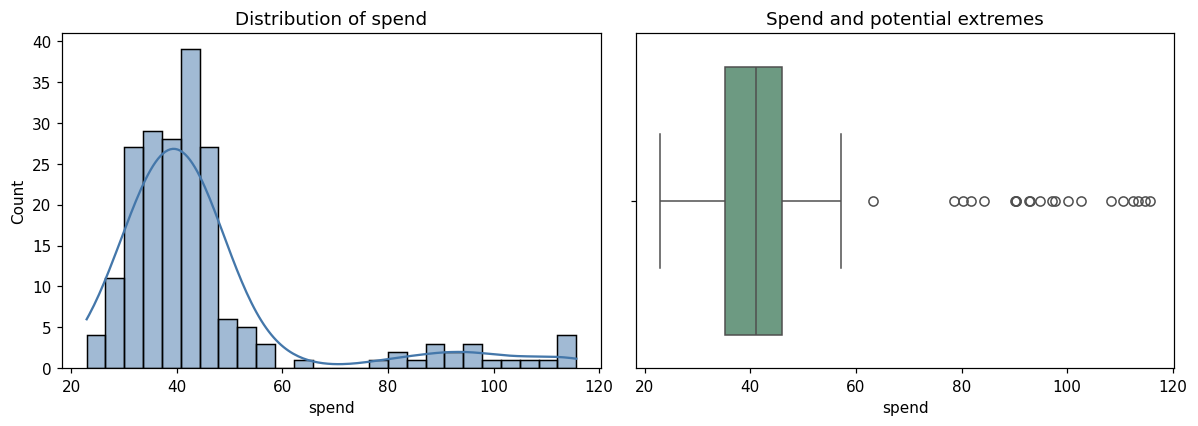

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=profile, x="spend", kde=True, color="#4477AA", ax=axes[0])
axes[0].set_title("Distribution of spend")
sns.boxplot(data=profile, x="spend", color="#66A182", ax=axes[1])
axes[1].set_title("Spend and potential extremes")
plt.tight_layout()
plt.show()

## Numerical summaries and robust comparisons
- The mean uses every value and is sensitive to extreme observations.
- The median is the 50th percentile and is more robust to long tails.
- Standard deviation measures spread around the mean; IQR measures the middle 50%.
- A high outlier flag does not automatically justify deleting a record.

In [3]:
summary = profile["spend"].agg(["count", "mean", "median", "std", "min", "max"])
summary.loc["q25"] = profile["spend"].quantile(.25)
summary.loc["q75"] = profile["spend"].quantile(.75)
summary.loc["iqr"] = summary.loc["q75"] - summary.loc["q25"]
display(summary.to_frame("spend"))

# Compare the mean and median before and after excluding the top 1% as a sensitivity check.
cutoff = profile["spend"].quantile(.99)
trimmed = profile.loc[profile["spend"] <= cutoff, "spend"]
print("Original mean / median:", round(profile.spend.mean(), 2), round(profile.spend.median(), 2))
print("Sensitivity-check mean / median:", round(trimmed.mean(), 2), round(trimmed.median(), 2))

Original mean / median: 45.34 40.98
Sensitivity-check mean / median: 44.63 40.76


,spend
count,200.000000
mean,45.338946
median,40.978105
std,18.987399
min,22.943630
max,115.683989
q25,35.210907
q75,45.960427
iqr,10.749521


## Categorical profiling
For categories, inspect counts and percentages. Small category counts can be hidden or grouped for readable charts, but do not remove them from the underlying data without a documented rule.

/mnt/data/data_science_data_work/6. Exploratory Data Analysis/15_descriptive_statistics_and_distributions.ipynb:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "# Descriptive Statistics and Distributions\n",


,count,percent
group,,
A,52,43.333333
B,45,37.500000
C,17,14.166667
Unknown,6,5.000000


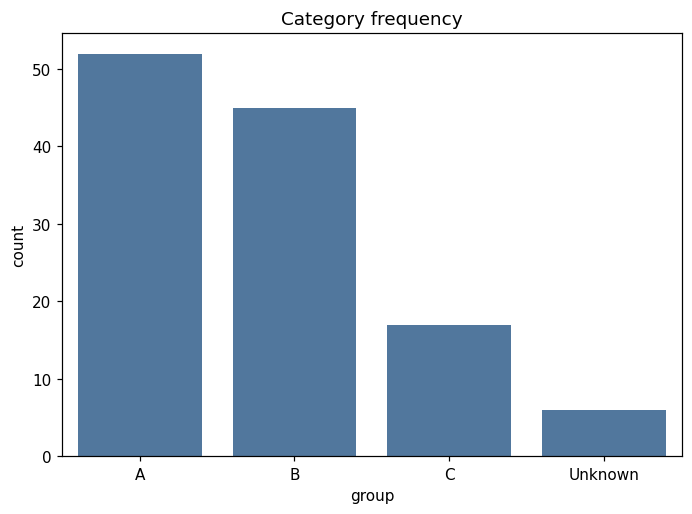

In [4]:
category_demo = pd.Series(rng.choice(["A", "B", "C", "Unknown"], size=120, p=[.45, .35, .15, .05]), name="group")
counts = category_demo.value_counts(dropna=False).rename_axis("group").to_frame("count")
counts["percent"] = counts["count"] / counts["count"].sum() * 100
display(counts)
sns.countplot(x=category_demo, order=category_demo.value_counts().index, color="#4477AA")
plt.title("Category frequency")
plt.tight_layout()
plt.show()

## Practice
Calculate mean, median, IQR, and missing count for a numeric column, then draw a histogram and a boxplot.

{'mean': np.float64(21.0), 'median': np.float64(12.0), 'iqr': np.float64(4.5), 'missing': 1}


/mnt/data/data_science_data_work/6. Exploratory Data Analysis/15_descriptive_statistics_and_distributions.ipynb:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "metadata": {},


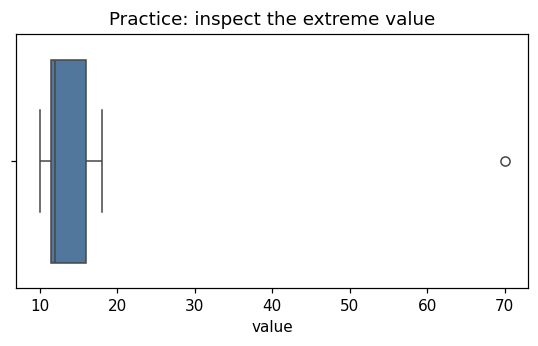

In [5]:
demo = pd.Series([10, 11, 12, 12, 14, 18, 70, np.nan], name="value")
print({"mean": demo.mean(), "median": demo.median(), "iqr": demo.quantile(.75)-demo.quantile(.25), "missing": int(demo.isna().sum())})
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(x=demo, color="#4477AA", ax=ax)
ax.set_title("Practice: inspect the extreme value")
plt.show()